COU07506 — Week 1

Lab 0: Setting Up the DSP Laboratory; First Signals

Name:Albert Eidaima Lyimo

Registration Number:240242425395

Date: 23 November 2026

https://github.com/Albert792/COU07506-labs.git


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP laboratory is ready!")

DSP laboratory is ready!


Task 1.1 - Your First Notebook

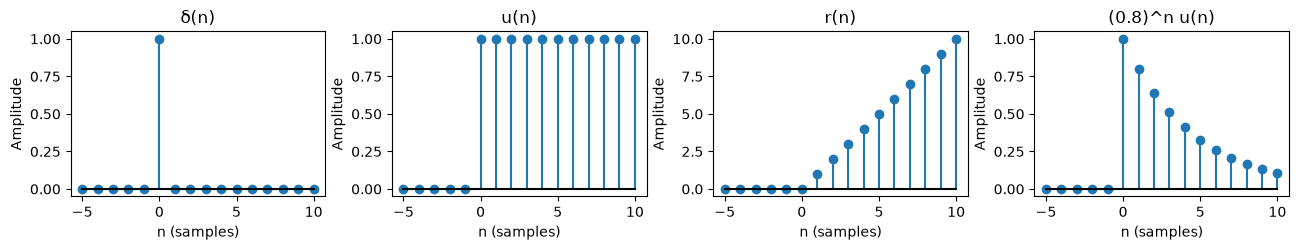

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step  = (n >= 0).astype(float)      # unit step
ramp  = n * step                    # unit ramp
expo  = 0.8**n * step               # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

Task 1.2 - Change the parameters

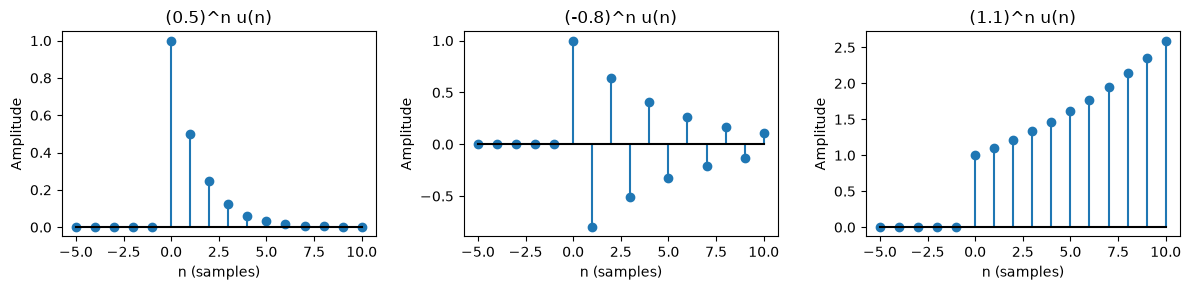

In [3]:
n = np.arange(-5, 11)
step = (n >= 0).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = (a**n) * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

## Analysis Question 3
When \(a = 1.1\), the sequence \((1.1)^n u(n)\) keeps growing as the sample index \(n\) increases. Since the values continue to increase without a limit, their absolute sum does not converge. Therefore, the sequence is not absolutely summable. If it is used as the impulse response of a system, the system is unstable because even a bounded input can produce an unbounded output. This means the system does not satisfy the BIBO stability condition.

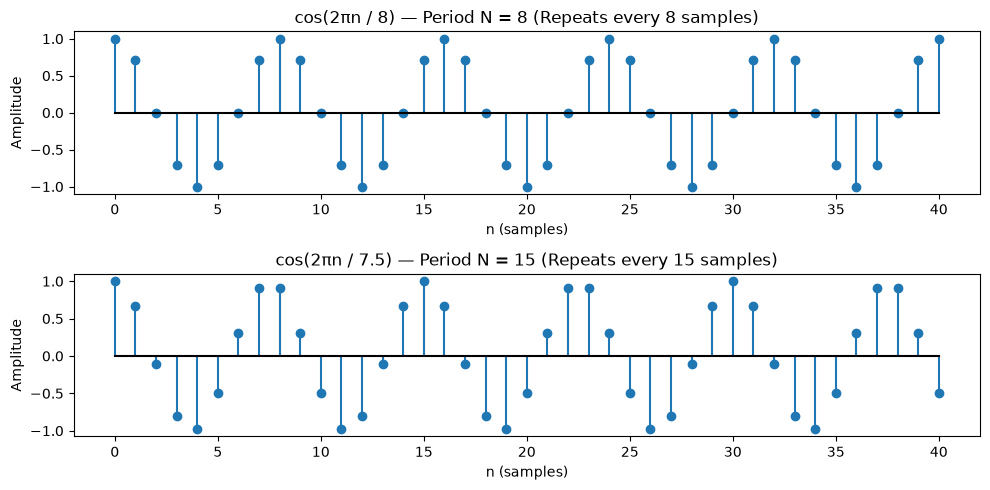

In [4]:
n = np.arange(0, 41)
x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("cos(2πn / 8) — Period N = 8 (Repeats every 8 samples)")
axes[0].set_xlabel("n (samples)")
axes[0].set_ylabel("Amplitude")

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("cos(2πn / 7.5) — Period N = 15 (Repeats every 15 samples)")
axes[1].set_xlabel("n (samples)")
axes[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

## Analysis Question 2
A discrete-time signal \(x(n)\) is defined only at specific integer sample points, such as 0, 1, 2, and so on. It has no values between these points. For this reason, a stem plot is more suitable because it shows each sample separately without connecting them. On the other hand, plt.plot joins the sample points with lines, which may give the impression that the signal exists continuously between samples. Therefore, a stem plot is the better choice for representing a discrete-time signal.

 Task 1.3 — Working with Audio

C:\Users\wizzy\AppData\Local\Temp\ipykernel_1960\366366691.py:6: WavFileWarning: Chunk (non-data) not understood, skipping it.
  fs, x = wavfile.read(fname)


fs = 16000 Hz, duration = 5.44 s, samples = 87040


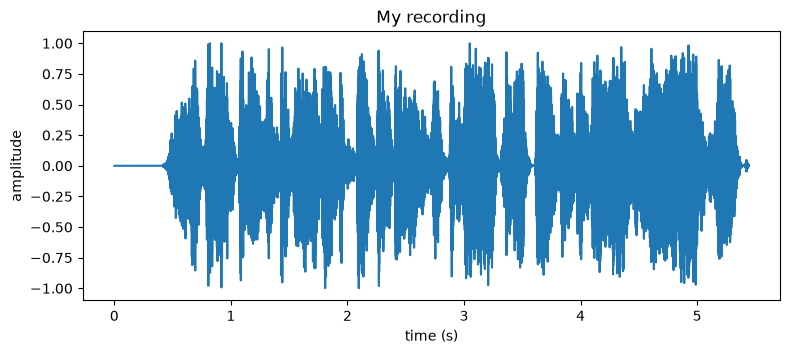

In [5]:
import os
from IPython.display import Audio

fname = "my_voice.wav"  
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)        # stereo -> mono
    x = x / np.max(np.abs(x))     # normalise to [-1, 1]
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.show()

Audio(x, rate=fs)

 ## Analysis Question 1
The audio recording was sampled at a rate of 16,000 Hz, meaning that 16,000 samples were recorded every second. The recording lasted for 5.44 seconds and contained 87,040 samples in total. If the same sampling rate is used to record one minute of mono audio, a total of 960,000 samples would be needed. This is calculated by multiplying the sampling rate of 16,000 samples per second by 60 seconds.